# Fear is contagious too: analysis, results and demonstration
**CITS4403 group project · coupled SIR + risk-perception contagion on N = 1000 networks**

This notebook is the executable companion to the report. It states the research
question and hypotheses, checks the committed sweep data, validates the engine
live, reproduces every headline result with numbers and figures, runs short
live demonstrations suitable for the 10-minute project demo, and records
limitations. Code, equations, text and visualisations are kept together so the
analysis reads as one coherent account.

**How to run:** from the repository root with `requirements.txt` installed,
open this notebook and *Run All*. Inputs live in `notebook_output/data/`
(Kaggle sweep outputs plus the mean-field reference). Expected runtime is a
few minutes; the slowest cells are the live N = 1000 demonstrations.

**Frozen model specification:** N = 1000 nodes; β = 0.12 per infected edge per
step; γ = 0.05 recovery probability per step; fear threshold θ = 0.5; caution
effectiveness q = 0.8; broadcast trigger prevalence 0.02; hub pool = top 10%
by degree; 10 initially infected nodes. Topologies: WS (k = 6, p = 0.1),
BA (m = 3), degree-matched ER (p = 6/(n−1)). Final size means the **fraction
of nodes ever infected**, not peak prevalence.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run this notebook from the repo root or notebooks/."
sys.path.insert(0, str(ROOT))
DATA = ROOT / "notebook_output" / "data"

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
})
from src.simulation import SimParams, run_coupled

SPEC = dict(N=1000, beta=0.12, gamma=0.05, theta=0.5, q=0.8,
            prev_thresh=0.02, hub_frac=0.1, init_infected=10)
print("ROOT:", ROOT)
print("SPEC:", SPEC)


ROOT: C:\Users\truon\AppData\Local\Temp\opencode\issue-nb04
SPEC: {'N': 1000, 'beta': 0.12, 'gamma': 0.05, 'theta': 0.5, 'q': 0.8, 'prev_thresh': 0.02, 'hub_frac': 0.1, 'init_infected': 10}


## 1 · Data inventory and integrity checks
Three committed sweep files plus the mean-field reference. Row counts,
missing values, duplicates and parameter coverage are asserted so the
notebook fails loudly on corrupted inputs.


In [2]:
files = {"pilot_full": 9090, "zoom_h2": 3600, "beta_sweep": 600,
         "mean_field_runs": 80}
frames = {}
for name, expected in files.items():
    df = pd.read_csv(DATA / f"{name}.csv")
    assert len(df) == expected, (name, len(df))
    assert not df.isna().any().any(), name
    frames[name] = df
    print(f"{name}: {len(df)} rows, {len(df.columns)} cols, "
          f"full-row dupes={df.duplicated().sum()}")
pilot, zoom, beta_df, mf_runs = (frames[k] for k in files)
mf_summary = pd.read_csv(DATA / "mean_field_summary.csv")
print("\npilot topologies:", sorted(pilot.topology.unique()))
print("pilot rules:", sorted(pilot.rule.unique()))
print("seeds by file - pilot:", pilot.seed.nunique(), "| zoom:", zoom.seed.nunique(),
      "| beta:", beta_df.seed.nunique(), "| mean-field:", mf_runs.seed.nunique())


pilot_full: 9090 rows, 16 cols, full-row dupes=0
zoom_h2: 3600 rows, 16 cols, full-row dupes=0
beta_sweep: 600 rows, 16 cols, full-row dupes=0
mean_field_runs: 80 rows, 3 cols, full-row dupes=0

pilot topologies: ['ba', 'er', 'ws']
pilot rules: ['broadcast', 'broadcast_hub', 'imitation', 'none', 'observation']
seeds by file - pilot: 30 | zoom: 30 | beta: 20 | mean-field: 20


## 2 · Research question and hypotheses
**RQ:** which behavioural-feedback rule minimises epidemic final size *per
unit of social cost* (contacts forgone)? The candidates are **observation**
(local: fear from infected neighbours), **imitation** (social copying of
cautious neighbours), and **broadcast** (global prevalence trigger, uniform
or hub-targeted).

- **H1:** intermediate fear-memory decay produces multi-wave dynamics.
- **H2:** on scale-free (BA) networks hub-targeted nudges dominate; on
  homogeneous networks they do not.
- **H3:** imitation amplifies and overshoots, producing oscillations.

Each hypothesis maps to a section below (§4, §6, §4–§5); the RQ is answered
in §5 and stress-tested in §7. First, the engine must earn trust.


In [3]:
r0 = run_coupled(SimParams(topology="ws", n=300, seed=1, beta=0.0, rule="none"))
r1 = run_coupled(SimParams(topology="ws", n=300, seed=1, gamma=1.0, rule="none"))
a = run_coupled(SimParams(topology="ba", n=300, seed=42, rule="observation"))
b = run_coupled(SimParams(topology="ba", n=300, seed=42, rule="observation"))
print(f"beta=0  -> final_size = {r0['final_size']:.4f} (expect 10/300 = 0.0333)")
print(f"gamma=1 -> duration = {r1['duration']} steps (fast recovery)")
print(f"determinism: {a['final_size']:.6f} == {b['final_size']:.6f} -> "
      f"{a['final_size'] == b['final_size']}")
assert abs(r0["final_size"] - 10 / 300) < 1e-9
assert r1["duration"] <= 5
assert a["final_size"] == b["final_size"]
print("engine validation checks passed")


beta=0  -> final_size = 0.0333 (expect 10/300 = 0.0333)
gamma=1 -> duration = 2 steps (fast recovery)
determinism: 0.613333 == 0.613333 -> True
engine validation checks passed


## 3 · Mean-field validation
For `rule='none'`, the network simulation should track a homogeneous SIR
reference. The ODE uses population fractions with incidence $\\beta k s i$
($k = 6$, the network mean degree) and recovery $\gamma i$:

$$\dot s = -\beta k s i, \qquad \dot i = \beta k s i - \gamma i,
  \qquad \dot r = \gamma i.$$

This is a reference approximation, not an exact limit: the engine uses
synchronous discrete-time Bernoulli transmission on a fixed clustered WS
network, while the ODE assumes continuous time and homogeneous mixing.
A gap is expected; its size is itself reportable.


recomputed ODE final @beta=0.03: 0.969848 vs committed 0.969848
 beta   mean    std  ode_final_size
 0.03 0.7512 0.0751          0.9698
 0.06 0.9810 0.0092          0.9993
 0.12 0.9993 0.0011          1.0000
 0.20 1.0000 0.0000          1.0000


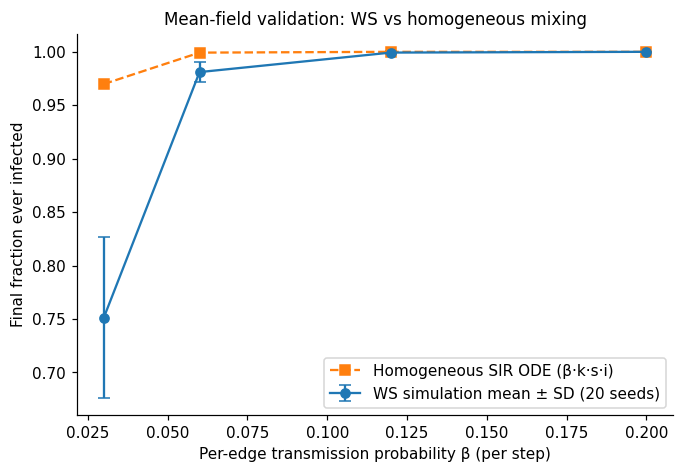

In [4]:
from scipy.integrate import solve_ivp

def ode_final(beta, K=6, gamma=0.05, N=1000, I0=10):
    def rhs(t, y):
        s, i, r = y
        inc = beta * K * s * i
        return [-inc, inc - gamma * i, gamma * i]
    sol = solve_ivp(rhs, (0, 5000), [1 - I0 / N, I0 / N, 0.0],
                    rtol=1e-9, atol=1e-11)
    assert sol.success and abs(sol.y[:, -1].sum() - 1) < 1e-7
    return 1 - sol.y[0, -1]

check = ode_final(0.03)
ref = float(mf_summary.loc[mf_summary.beta == 0.03, "ode_final_size"].iloc[0])
print(f"recomputed ODE final @beta=0.03: {check:.6f} vs committed {ref:.6f}")
assert abs(check - ref) < 1e-6

tab = mf_runs.groupby("beta")["final_size"].agg(["mean", "std"]).reset_index()
tab = tab.merge(mf_summary[["beta", "ode_final_size"]], on="beta")
assert len(tab) == 4
print(tab.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(tab.beta, tab["mean"], yerr=tab["std"], fmt="o-", capsize=4,
            label="WS simulation mean ± SD (20 seeds)")
ax.plot(tab.beta, tab.ode_final_size, "s--", label="Homogeneous SIR ODE (β·k·s·i)")
ax.set(xlabel="Per-edge transmission probability β (per step)",
       ylabel="Final fraction ever infected",
       title="Mean-field validation: WS vs homogeneous mixing")
ax.legend()
plt.show()


## 4 · Phase structure: coupling × memory
Each cell below averages 30 seeds. Upper row: mean final size under local
observation. Lower row: mean detected wave count under global uniform
broadcast (peak-finding with prominence max(0.01, 0.2 × peak), ≥ 10 steps
apart, which is an algorithmic count rather than a claim of independent
outbreaks).


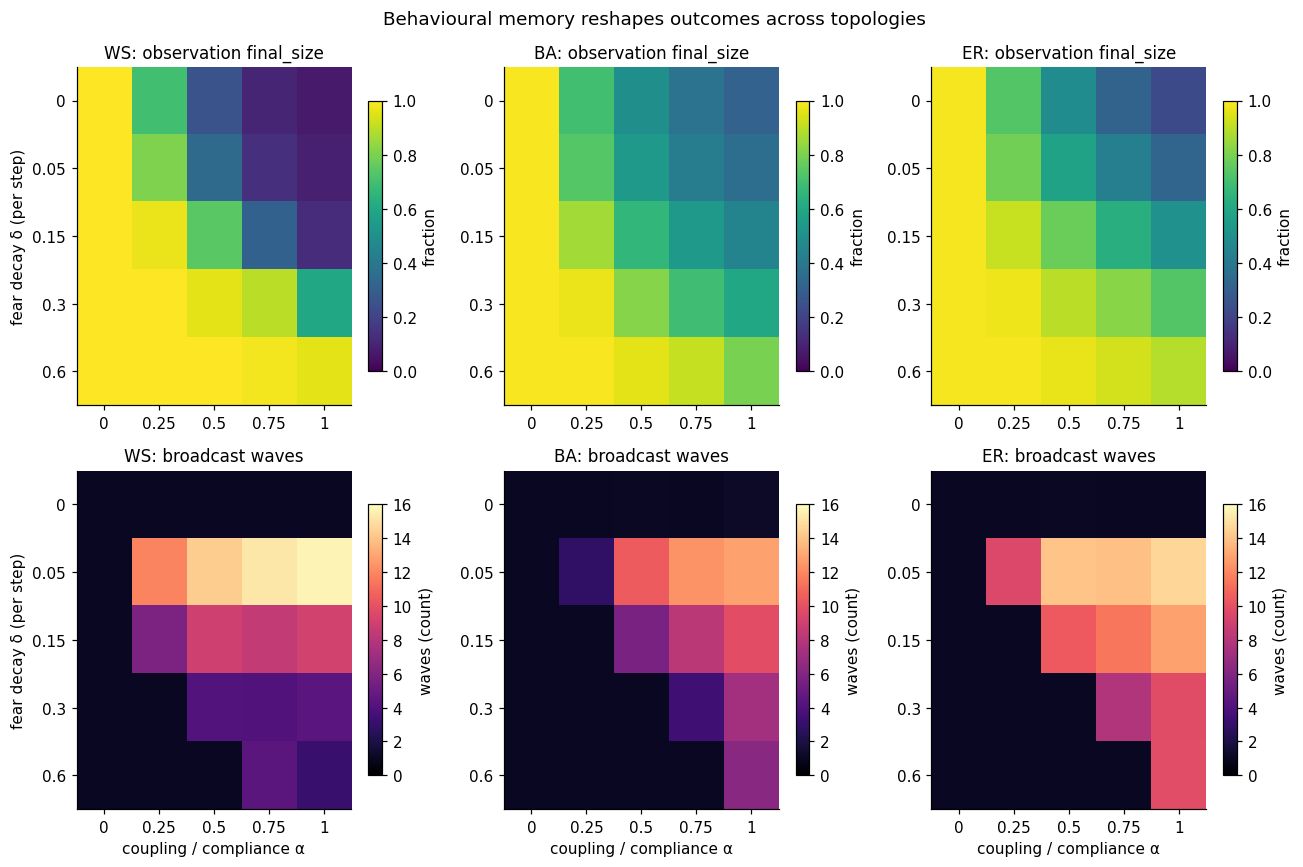

broadcast detected waves by fear decay δ:
         mean  max
delta            
0.00    1.03    3
0.05   10.05   19
0.15    6.39   19
0.30    3.26   16
0.60    2.31   15

mean oscillation index by rule:
 rule
broadcast        0.783
broadcast_hub    1.323
imitation        1.367
none             1.456
observation      1.237


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cfgs = [("observation", "final_size", "viridis", 0, 1),
        ("broadcast", "waves", "magma", 0, 16)]
for col, t in enumerate(["ws", "ba", "er"]):
    for row, (rule, metric, cmap, lo, hi) in enumerate(cfgs):
        piv = (pilot[(pilot.rule == rule) & (pilot.topology == t)]
               .pivot_table(index="delta", columns="alpha",
                            values=metric, aggfunc="mean"))
        assert piv.shape == (5, 5) and piv.notna().all().all()
        ax = axes[row, col]
        im = ax.imshow(piv.values, vmin=lo, vmax=hi, cmap=cmap, aspect="auto")
        ax.set_xticks(range(5), [f"{a:g}" for a in piv.columns])
        ax.set_yticks(range(5), [f"{d:g}" for d in piv.index])
        ax.set_title(f"{t.upper()}: {rule} {metric}")
        if row == 1:
            ax.set_xlabel("coupling / compliance α")
        if col == 0:
            ax.set_ylabel("fear decay δ (per step)")
        plt.colorbar(im, ax=ax, shrink=0.8,
                     label=("fraction" if row == 0 else "waves (count)"))
plt.suptitle("Behavioural memory reshapes outcomes across topologies")
plt.tight_layout()
plt.show()

bw = pilot[pilot.rule == "broadcast"].groupby("delta")["waves"].agg(["mean", "max"])
print("broadcast detected waves by fear decay δ:\n", bw.round(2).to_string())
print("\nmean oscillation index by rule:\n",
      pilot.groupby("rule")["oscillation"].mean().round(3).to_string())


**Reading the panels.** The sharpest regime change is the *broadcast
paradox*: with perfect memory (δ = 0) the campaign holds prevalence down
cleanly (≈1 wave everywhere), while a small positive decay (δ = 0.05) lets
protection lapse and reignite, averaging 10.05 waves and peaking at 19.
Stronger decay then damps the system back toward fewer, larger outbreaks.
For observation the gradient is monotonic: on WS at full coupling (α = 1),
mean final size rises from 0.073 at δ = 0 to 0.961 at δ = 0.6. Memory, not
just responsiveness, does the protective work.

**H1 verdict (reframed):** intermediate decay maximises multi-wave dynamics
in the *broadcast* channel, but there is no universal phase transition,
since observation suppresses monotonically. **H3 (partial):** imitation has the
highest oscillation index among the rules (1.367), yet the no-behaviour
baseline scores higher still (1.456), because the index (std/mean) also
rewards a single tall peak. Imitation wobbles more than its siblings, but
the metric cannot isolate genuine overshoot from peakedness.


## 5 · RQ: which rule minimises final size per unit social cost?
Efficiency = (baseline final − rule final) / (social cost + 1), averaged over
the positive-coupling grid (α ∈ {0.25, 0.5, 0.75, 1}, five δ values, 30 seeds
= 600 runs per point). Social cost is the Σ cautious-nodes × mean-degree ×
q/2 proxy in edge-days forgone (q = 0.8), not measured economic loss.


topology          rule  final_size  social_cost  reduction       eff
      ws   observation   6.028e-01    7.923e+04  3.965e-01 5.005e-06
      ba   observation   6.602e-01    1.352e+05  3.306e-01 2.445e-06
      er   observation   6.955e-01    1.334e+05  2.920e-01 2.189e-06
      ba broadcast_hub   9.441e-01    2.733e+04  4.677e-02 1.711e-06
      ws     imitation   6.569e-01    2.504e+05  3.424e-01 1.367e-06
      ba     imitation   6.515e-01    3.062e+05  3.393e-01 1.108e-06
      er     imitation   6.869e-01    3.282e+05  3.007e-01 9.163e-07
      ws     broadcast   4.997e-01    6.359e+05  4.997e-01 7.858e-07
      ba     broadcast   5.473e-01    5.835e+05  4.436e-01 7.602e-07
      er     broadcast   5.500e-01    6.466e+05  4.375e-01 6.767e-07
      ws broadcast_hub   9.855e-01    2.899e+04  1.387e-02 4.785e-07
      er broadcast_hub   9.767e-01    2.550e+04  1.082e-02 4.243e-07
WS: most cost-efficient = observation (eff = 5.00e-06 infections averted per edge-day)
BA: most cost-ef

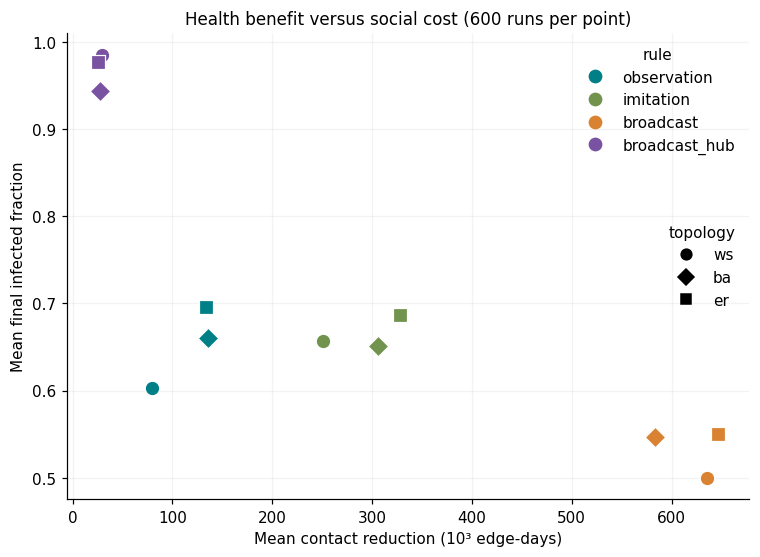

In [6]:
base = pilot[pilot.rule == "none"].groupby("topology")["final_size"].mean()
agg = (pilot[pilot.alpha > 0].groupby(["topology", "rule"])
       [["final_size", "social_cost"]].mean().reset_index())
agg["reduction"] = agg.apply(lambda r: base.loc[r["topology"]] - r["final_size"],
                             axis=1)
agg["eff"] = agg["reduction"] / (agg["social_cost"] + 1)
agg = agg.sort_values("eff", ascending=False)
print(agg.to_string(index=False, float_format=lambda x: f"{x:.3e}"))
for topo in ["ws", "ba", "er"]:
    winner = agg[agg.topology == topo].iloc[0]
    assert winner["rule"] == "observation", topo
    print(f"{topo.upper()}: most cost-efficient = {winner['rule']} "
          f"(eff = {winner['eff']:.2e} infections averted per edge-day)")

colors = {"observation": "#007f86", "imitation": "#72934e",
          "broadcast": "#d98332", "broadcast_hub": "#7952a2"}
markers = {"ws": "o", "ba": "D", "er": "s"}
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in agg.iterrows():
    ax.scatter(r["social_cost"] / 1000, r["final_size"], c=colors[r["rule"]],
               marker=markers[r["topology"]], s=90, edgecolors="white",
               linewidths=0.8, zorder=3)
ax.set(xlabel="Mean contact reduction (10³ edge-days)",
       ylabel="Mean final infected fraction",
       title="Health benefit versus social cost (600 runs per point)")
ax.grid(alpha=0.15)
leg1 = ax.legend([Line2D([], [], marker="o", ls="", color=c, markersize=8,
                          label=k) for k, c in colors.items()],
                 list(colors), title="rule", loc="upper right", frameon=False)
ax.add_artist(leg1)
ax.legend([Line2D([], [], marker=m, ls="", color="k", markersize=7,
                   label=t.upper()) for t, m in markers.items()],
          list(markers), title="topology", loc="center right", frameon=False)
plt.show()


**Answer to the RQ: local observation wins everywhere**, with ≈5.0e-6
infections averted per edge-day on WS, ≈2.4e-6 on BA and ≈2.2e-6 on ER. Uniform
broadcast reaches the smallest epidemics (WS final ≈ 0.50 from a ≈ 1.0
baseline) but at ≈ 636k edge-days, roughly 8× the cost of observation for a
comparable gain. Hub broadcast is cheap (≈ 26–29k edge-days) but barely moves
final size at pilot scale, because targeting a few nodes cannot substitute for
broad protection. The points summarise parameter grids, not an optimisation
frontier.


## 6 · H2: hub-targeted versus uniform nudges at equal budgets
`zoom_h2.csv` varies the compliance budget (fraction of nodes) for uniform
broadcast and broadcast restricted to the top 10% by degree. Each point pools
30 seeds × 4 decay values = 120 runs. At budgets ≤ 0.10 both policies reach
equal expected node counts; above 0.10 the hub pool saturates while uniform
coverage keeps growing, so the comparison is no longer equal coverage.


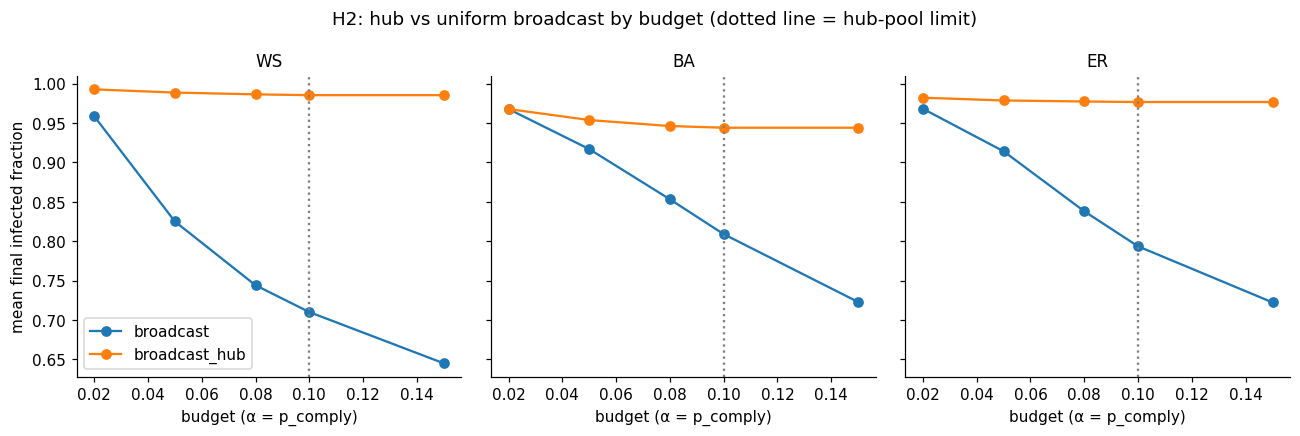

                     final_size  social_cost       eff
rule          alpha                                   
broadcast     0.02    9.678e-01    7.930e+04 2.910e-07
              0.05    9.169e-01    1.234e+05 5.988e-07
              0.08    8.532e-01    1.526e+05 9.021e-07
              0.10    8.090e-01    1.753e+05 1.038e-06
              0.15    7.228e-01    2.299e+05 1.166e-06
broadcast_hub 0.02    9.677e-01    2.010e+04 1.149e-06
              0.05    9.538e-01    2.581e+04 1.434e-06
              0.08    9.462e-01    2.794e+04 1.598e-06
              0.10    9.440e-01    2.830e+04 1.654e-06
              0.15    9.440e-01    2.830e+04 1.654e-06
hub efficiency beats uniform on BA at every budget: confirmed
BA hub-policy final size at budgets ≥ 0.10:
 alpha
0.10    0.944
0.15    0.944


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, t in zip(axes, ["ws", "ba", "er"]):
    for rule in ["broadcast", "broadcast_hub"]:
        sub = (zoom[(zoom.topology == t) & (zoom.rule == rule)]
               .groupby("alpha")["final_size"].mean())
        ax.plot(sub.index, sub.values, marker="o", label=rule)
    ax.axvline(0.1, color="grey", ls=":")
    ax.set_title(t.upper())
    ax.set_xlabel("budget (α = p_comply)")
axes[0].set_ylabel("mean final infected fraction")
axes[0].legend()
plt.suptitle("H2: hub vs uniform broadcast by budget (dotted line = hub-pool limit)")
plt.tight_layout()
plt.show()

baseba = base.loc["ba"]
zb = (zoom[zoom.topology == "ba"].groupby(["rule", "alpha"])
      [["final_size", "social_cost"]].mean())
zb["eff"] = (baseba - zb["final_size"]) / (zb["social_cost"] + 1)
print(zb.to_string(float_format=lambda x: f"{x:.3e}"))
for budget in sorted(zoom.alpha.unique()):
    assert zb.loc[("broadcast_hub", budget), "eff"] > zb.loc[("broadcast", budget), "eff"], budget
print("hub efficiency beats uniform on BA at every budget: confirmed")
sat = (zoom[(zoom.topology == "ba") & (zoom.rule == "broadcast_hub")
            & (zoom.alpha >= 0.1)].groupby("alpha")["final_size"].mean())
print("BA hub-policy final size at budgets ≥ 0.10:\n", sat.round(3).to_string())


**H2 verdict (refined, not simply confirmed):** per unit cost, hub
targeting beats uniform broadcast on BA at *every* budget, yet its raw final
size stalls at 0.944 from budget 0.10 upward because the 10% hub pool is
exhausted, while uniform broadcast keeps improving (0.809 → 0.723). That
ceiling is a property of the chosen hub-pool rule, not evidence that hubs
cannot matter more under a different targeting policy. On homogeneous WS/ER
networks the hub line stays near 0.98: with no real hubs, hub-targeting is
dead weight. So H2 holds for *efficiency* on heterogeneous networks, with an
explicit saturation caveat for *absolute* benefit.


## 7 · Robustness: transmission sweep and topology
`beta_sweep.csv` varies per-edge transmission β from 0.03 to 0.20 (20 seeds),
comparing no behaviour with observation at α = 0.75, δ = 0.10. Bands show ±1
sample SD across seeds (descriptive variability, not confidence intervals).


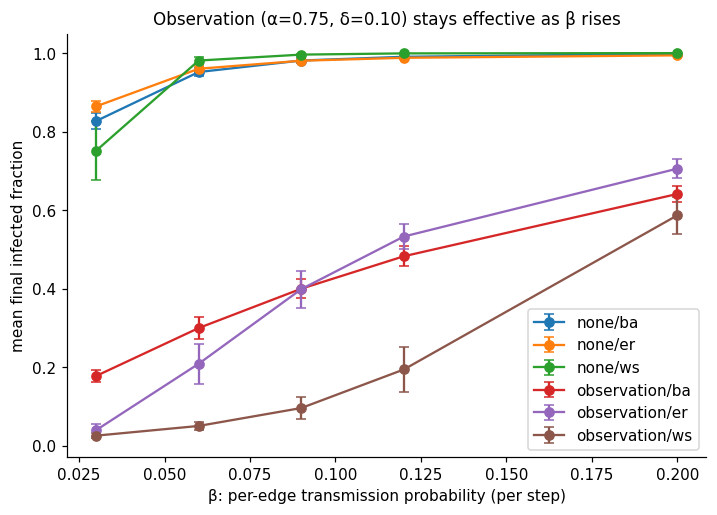

lowest final size under observation, by β:
 beta
0.03    ws
0.06    ws
0.09    ws
0.12    ws
0.20    ws
WS is the most suppressible topology at every β: confirmed


In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for (rule, topo), sub in beta_df.groupby(["rule", "topology"]):
    g = sub.groupby("beta")["final_size"].agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3,
                label=f"{rule}/{topo}")
ax.set(xlabel="β: per-edge transmission probability (per step)",
       ylabel="mean final infected fraction",
       title="Observation (α=0.75, δ=0.10) stays effective as β rises")
ax.legend()
plt.show()
obs = beta_df[beta_df.rule == "observation"]
mins = (obs.groupby(["beta", "topology"])["final_size"].mean()
        .unstack().idxmin(axis=1))
print("lowest final size under observation, by β:\n", mins.to_string())
assert (mins == "ws").all()
print("WS is the most suppressible topology at every β: confirmed")


Without behaviour, all topologies saturate near complete infection
by β = 0.09. Observation (at one fixed, untuned setting) holds WS below 0.6
even at β = 0.20, which is above the pilot β = 0.12, and WS is the easiest topology
to suppress at every tested β, consistent with its clustered lattice slowing
spread. The ranking BA/ER above WS is stable, so the RQ answer does not hinge
on a knife-edge parameter choice.


## 8 · Live demonstrations (10-minute demo run-of-show)
Three short demos below re-run the merged engine live: (A) a same-seed
rule comparison, (B) trajectory shapes that motivate the phase panels, and
(C) sensitivity to the broadcast trigger assumption. Suggested timing:
1 min motivation + RQ, 2 min model/equations, 4 min results (§4–§7 figures),
2 min live demos, 1 min limitations.


In [9]:
rows = []
for rule in ["none", "observation", "imitation", "broadcast", "broadcast_hub"]:
    out = run_coupled(SimParams(topology="ws", n=1000, seed=11, beta=0.12,
                                rule=rule))
    rows.append((rule, round(out["final_size"], 3), int(out["social_cost"]),
                 out["waves"], out["duration"]))
demoA = pd.DataFrame(rows, columns=["rule", "final_size",
                                    "social_cost (edge-days)", "waves",
                                    "duration (steps)"])
print("Demo A: same seed (11), WS, N=1000, β=0.12:")
print(demoA.to_string(index=False))


Demo A: same seed (11), WS, N=1000, β=0.12:
         rule  final_size  social_cost (edge-days)  waves  duration (steps)
         none       1.000                        0      1               141
  observation       0.631                   114048      1               257
    imitation       0.642                   258424      1               135
    broadcast       0.475                   947798     11               500
broadcast_hub       0.976                    25200      1               148


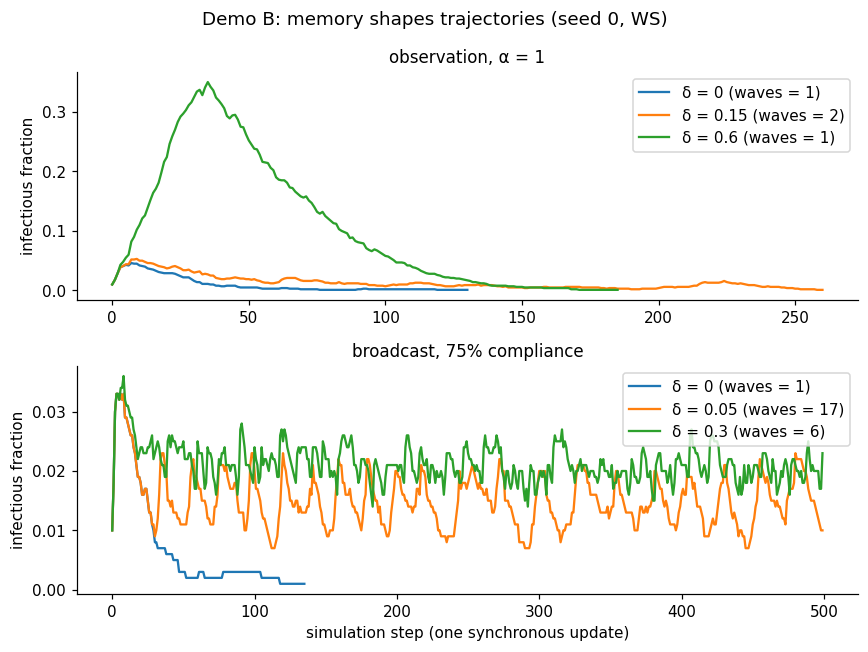

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
cases = [("observation", 1.0, (0.0, 0.15, 0.6), "observation, α = 1"),
         ("broadcast", 0.75, (0.0, 0.05, 0.3), "broadcast, 75% compliance")]
for ax, (rule, alpha, deltas, title) in zip(axes, cases):
    for d in deltas:
        out = run_coupled(SimParams(topology="ws", n=1000, seed=0, beta=0.12,
                                    rule=rule, alpha=alpha, p_comply=alpha,
                                    delta=d))
        ax.plot(out["prev_series"], label=f"δ = {d:g} (waves = {out['waves']})")
    ax.set_title(title)
    ax.set_ylabel("infectious fraction")
    ax.legend()
axes[1].set_xlabel("simulation step (one synchronous update)")
plt.suptitle("Demo B: memory shapes trajectories (seed 0, WS)")
plt.tight_layout()
plt.show()


In [11]:
print("Demo C: broadcast trigger sensitivity (WS, N=300, seed 0, "
      "α=0.75, δ=0.05):")
for thr in (0.01, 0.02, 0.05):
    out = run_coupled(SimParams(topology="ws", n=300, seed=0, beta=0.12,
                                rule="broadcast", alpha=0.75, delta=0.05,
                                prev_thresh=thr))
    print(f"  trigger={thr}: final={out['final_size']:.3f}, "
          f"waves={out['waves']}, duration={out['duration']}")


Demo C: broadcast trigger sensitivity (WS, N=300, seed 0, α=0.75, δ=0.05):
  trigger=0.01: final=0.120, waves=3, duration=227
  trigger=0.02: final=0.227, waves=8, duration=351


  trigger=0.05: final=0.743, waves=15, duration=441


## 9 · Limitations
- **Synthetic networks only.** WS, BA and degree-matched ER do not capture
  real contact patterns; neither degree matching nor the homogeneous
  mean-field comparison validates against empirical networks. Findings are
  relative rankings, not predictions for real populations.
- **Fixed broadcast trigger (0.02).** Conclusions about repeated on/off
  responses may shift under a different or adaptive threshold (see Demo C
  for how sensitive the dynamics are).
- **Wave-count convention.** Detected waves use prominence
  max(0.01, 0.2 × peak) with ≥ 10 steps separation; low-amplitude
  oscillations may not count, and counted peaks are not independent
  outbreaks.
- **Hub-pool ceiling.** Hub broadcast reaches only the top 10% by degree:
  BA final size levels at 0.944 for budgets ≥ 0.10. Above-budget comparisons
  are not equal coverage.
- **Cost proxy.** Social cost counts cautious contact reduction in edge-days
  (mean degree, q = 0.8), not mobility or economic loss.
- **Discrete time, fixed seeds budget.** Synchronous Bernoulli updates with
  30 pilot / 20 sweep / 20 mean-field seeds; stochastic uncertainty is
  reported as sample SD, and rare-event tails are unexplored.
- **Single-parameter slices.** Demonstrations fix one seed and one topology;
  trajectories illustrate mechanisms, not universal behaviour.

**Extensions:** adaptive triggers, larger seed budgets, an empirical contact
network with subgraph sampling, and imitation with heterogeneous innovators.


## 10 · Conclusion
Local observation of sick contacts is the most cost-efficient rule on every
tested topology (≈2–5e-6 infections averted per edge-day); uniform broadcast
suppresses most but costs ≈8× more; hub-targeting wins on efficiency where
hubs exist yet saturates at the pool limit. Intermediate fear decay
maximises recurrent waves under broadcast (H1, reframed), imitation wobbles
most among the rules without clean overshoot evidence (H3, partial), and
hub efficiency dominates on BA with the stated ceiling (H2, refined). The
cell below stamps reproducibility.


In [12]:
import matplotlib as _mpl, scipy as _sp, networkx as _nx
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"matplotlib {_mpl.__version__}, scipy {_sp.__version__}, "
      f"networkx {_nx.__version__}")
print("rows:", {k: len(v) for k, v in
      {"pilot_full": pilot, "zoom_h2": zoom, "beta_sweep": beta_df,
       "mean_field_runs": mf_runs}.items()})
print("executed (UTC):", time.strftime("%Y-%m-%d %H:%M", time.gmtime()))
print("All inline assertions passed; figures and tables above are live outputs.")


numpy 2.3.3, pandas 2.3.3, matplotlib 3.10.7, scipy 1.16.2, networkx 3.5
rows: {'pilot_full': 9090, 'zoom_h2': 3600, 'beta_sweep': 600, 'mean_field_runs': 80}
executed (UTC): 2026-10-06 15:28
All inline assertions passed; figures and tables above are live outputs.
